# Adım 2: CNN Eğitimi (EfficientNet)

Bu defter şunları yapar:
1. Adım 1'de kaydettiğimiz **lezyon bazlı ayrımı** yükler
2. Görüntüleri modele hazırlar (yeniden boyutlandırma, veri çoğaltma)
3. **EfficientNetB0**'ı iki aşamada eğitir: önce yalnızca son katman, sonra modelin üst kısmı
4. Sınıf dengesizliği için **sınıf ağırlıkları** kullanır
5. Her turda **dengeli doğruluğu** ölçer, en iyi modeli Drive'a kaydeder
6. Modeli **doğrulama kümesinde** değerlendirir (test kümesine Adım 3'te dokunacağız)

**Başlamadan önce:** *Çalışma zamanı → Çalışma zamanı türünü değiştir → GPU* seç (T4 yeterli; L4 veya A100 varsa daha hızlı).

Toplam süre GPU'ya göre yaklaşık 20-40 dakika.

## 1. Ortam: GPU, Drive ve ayarlar

In [1]:
import os, json, glob, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import keras
from keras import layers

from google.colab import drive
drive.mount('/content/drive')
PROJE = '/content/drive/MyDrive/bitirme'

print('TensorFlow:', tf.__version__, '| Keras:', keras.__version__)
gpular = tf.config.list_physical_devices('GPU')
print('GPU:', gpular if gpular else 'YOK! Çalışma zamanı türünü GPU yapın.')

# ---- Ayarlar ----
MODEL_ADI   = 'cnn_b0'      # kaydedilecek dosya adı
IMG         = 224           # EfficientNetB0 giriş boyutu
BATCH       = 32
EPOCH_BAS   = 5             # 1. aşama: yalnızca sınıflandırma katmanı
EPOCH_INCE  = 25            # 2. aşama: ince ayar (erken durdurma ile kısalabilir)
LR_BAS      = 1e-3
LR_INCE     = 1e-4
ACILACAK    = 60            # 2. aşamada eğitime açılacak üst katman sayısı
SABIR       = 6             # dengeli doğruluk bu kadar tur artmazsa dur
TOHUM       = 42
AGIRLIKLAR  = 'imagenet'

keras.utils.set_random_seed(TOHUM)
if gpular:
    keras.mixed_precision.set_global_policy('mixed_float16')  # GPU'da yaklaşık 2 kat hız

SINIFLAR = ['akiec', 'bcc', 'bkl', 'df', 'mel', 'nv', 'vasc']   # sabit sıra, sonraki adımlar da bunu kullanacak
SINIF_ADI = {'akiec': 'Aktinik keratoz', 'bcc': 'Bazal hücreli karsinom', 'bkl': 'Benign keratoz',
             'df': 'Dermatofibrom', 'mel': 'Melanom', 'nv': 'Melanositik nevüs (ben)', 'vasc': 'Vasküler lezyon'}
os.makedirs(f'{PROJE}/models', exist_ok=True)
os.makedirs(f'{PROJE}/results', exist_ok=True)

Mounted at /content/drive
TensorFlow: 2.21.0 | Keras: 3.13.2
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Görüntüleri Drive'daki zip'ten aç ve ayrımı yükle
Kaggle'dan tekrar indirmiyoruz; Adım 1'de Drive'a kaydedilen zip'i Colab'ın hızlı diskine açıyoruz.

In [2]:
ZIP = f'{PROJE}/data/skin-cancer-mnist-ham10000.zip'
if not os.path.exists('/content/ham'):
    !unzip -q -n "{ZIP}" -d /content/ham
GORUNTU_KOKU = '/content/ham'

yollar = {}
for p in glob.glob(f'{GORUNTU_KOKU}/**/*.jpg', recursive=True):
    yollar.setdefault(os.path.splitext(os.path.basename(p))[0], p)

meta = pd.read_csv(f'{PROJE}/splits/ham10000_split.csv')
meta['path'] = meta['image_id'].map(yollar)
meta['y'] = meta['dx'].map({s: i for i, s in enumerate(SINIFLAR)})
assert meta['path'].notna().all(), 'Bazı görüntüler bulunamadı!'
assert meta.groupby('lesion_id')['split'].nunique().max() == 1, 'Ayrımda sızıntı var!'

egitim    = meta[meta['split'] == 'egitim'].reset_index(drop=True)
dogrulama = meta[meta['split'] == 'dogrulama'].reset_index(drop=True)
print('Eğitim:', len(egitim), '| Doğrulama:', len(dogrulama), '| Test (bu adımda kullanılmıyor):', (meta['split'] == 'test').sum())

Eğitim: 7054 | Doğrulama: 1464 | Test (bu adımda kullanılmıyor): 1497


## 3. Veri hattı ve veri çoğaltma
- Görüntüler 600×450'den 224×224'e küçültülür ve belleğe alınır (her turda diskten okunmaz, eğitim hızlanır).
- **Veri çoğaltma yalnızca eğitimde** uygulanır: rastgele çevirme, döndürme, yakınlaştırma ve kontrast. Kopyalar kaydedilmez; model her turda farklı varyasyonları görür.
- Doğrulama görüntüleri hiç değiştirilmez.

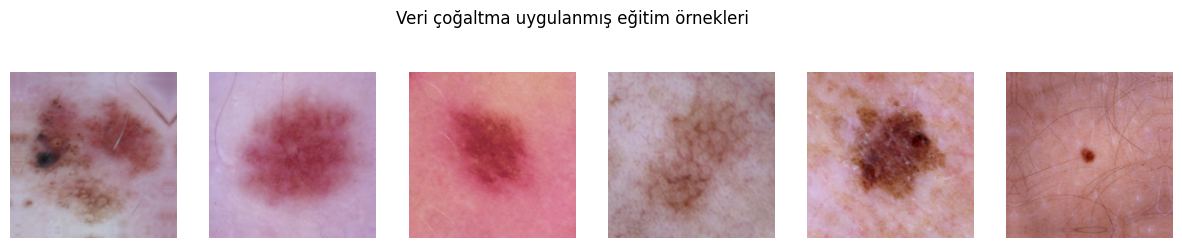

In [3]:
def oku(yol, y):
    goruntu = tf.io.decode_jpeg(tf.io.read_file(yol), channels=3)
    goruntu = tf.image.resize(goruntu, (IMG, IMG))
    return tf.cast(goruntu, tf.uint8), y   # bellekte az yer kaplasın diye uint8

cogaltma = keras.Sequential([
    layers.RandomFlip('horizontal_and_vertical'),
    layers.RandomRotation(0.25, fill_mode='reflect'),
    layers.RandomZoom(0.15, fill_mode='reflect'),
    layers.RandomContrast(0.15),
], name='veri_cogaltma')

def veri_hatti(df, egitim_mi):
    ds = tf.data.Dataset.from_tensor_slices((df['path'].values, df['y'].values))
    ds = ds.map(oku, num_parallel_calls=tf.data.AUTOTUNE).cache()
    if egitim_mi:
        ds = ds.shuffle(len(df), seed=TOHUM, reshuffle_each_iteration=True)
    ds = ds.batch(BATCH).map(lambda x, y: (tf.cast(x, tf.float32), y), num_parallel_calls=tf.data.AUTOTUNE)
    if egitim_mi:
        ds = ds.map(lambda x, y: (cogaltma(x, training=True), y), num_parallel_calls=tf.data.AUTOTUNE)
    return ds.prefetch(tf.data.AUTOTUNE)

egitim_ds    = veri_hatti(egitim, True)
dogrulama_ds = veri_hatti(dogrulama, False)
y_dogrulama  = dogrulama['y'].values

# Çoğaltılmış birkaç eğitim görüntüsüne göz at
ornek, _ = next(iter(egitim_ds))
fig, eksen = plt.subplots(1, 6, figsize=(15, 3))
for i in range(6):
    eksen[i].imshow(np.clip(ornek[i].numpy(), 0, 255).astype('uint8')); eksen[i].axis('off')
plt.suptitle('Veri çoğaltma uygulanmış eğitim örnekleri'); plt.show()

## 4. Sınıf ağırlıkları
Nadir sınıflarda yapılan hatalar daha çok cezalandırılır. Ağırlık = toplam / (sınıf sayısı × o sınıfın örnek sayısı).

In [4]:
from sklearn.utils.class_weight import compute_class_weight
agirlik = compute_class_weight('balanced', classes=np.arange(len(SINIFLAR)), y=egitim['y'].values)
SINIF_AGIRLIGI = {i: float(a) for i, a in enumerate(agirlik)}
print(pd.DataFrame({'sinif': [SINIF_ADI[s] for s in SINIFLAR],
                    'egitim_ornegi': np.bincount(egitim['y'], minlength=len(SINIFLAR)),
                    'agirlik': agirlik.round(2)}).to_string(index=False))

                  sinif  egitim_ornegi  agirlik
        Aktinik keratoz            233     4.32
 Bazal hücreli karsinom            365     2.76
         Benign keratoz            775     1.30
          Dermatofibrom             76    13.26
                Melanom            777     1.30
Melanositik nevüs (ben)           4730     0.21
        Vasküler lezyon             98    10.28


## 5. Modeli kur
- **EfficientNetB0**, ImageNet'teki milyonlarca görüntüyle önceden eğitilmiş olarak gelir (transfer öğrenme). Kendi ön işlemesini içerir; 0-255 aralığındaki görüntüyü doğrudan alır.
- Üstüne bir **Dropout** ve **7 sınıflı çıkış katmanı** ekliyoruz.
- Çıkış katmanı olasılık yerine **logit** (ham skor) verir. Adım 3'teki kalibrasyon (sıcaklık ölçekleme) logitlere ihtiyaç duyar; olasılığı softmax ile biz hesaplarız.
- Ara katmanlar düz bir yapıda tutulur; böylece Adım 3'te ısı haritası (Grad-CAM) ve Adım 4'te benzer vaka arşivi için içlerine erişebiliriz.

In [5]:
girdi = keras.Input(shape=(IMG, IMG, 3), name='goruntu')
govde = keras.applications.EfficientNetB0(include_top=False, weights=AGIRLIKLAR, input_tensor=girdi)
x = layers.GlobalAveragePooling2D(name='gap')(govde.output)      # Adım 4'te gömme vektörü buradan alınacak
x = layers.Dropout(0.3, name='dropout')(x)
cikti = layers.Dense(len(SINIFLAR), dtype='float32', name='logit')(x)
model = keras.Model(girdi, cikti, name=MODEL_ADI)

GOVDE_KATMANLARI = govde.layers[1:]   # giriş katmanı hariç
for k in GOVDE_KATMANLARI:
    k.trainable = False
print('Toplam katman:', len(model.layers), '| Gövde katmanı:', len(GOVDE_KATMANLARI))
print('Eğitilebilir parametre (1. aşama):', sum(int(np.prod(w.shape)) for w in model.trainable_weights))

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Toplam katman: 241 | Gövde katmanı: 237
Eğitilebilir parametre (1. aşama): 8967


## 6. Dengeli doğruluğu izleyen kayıt düzeneği
Keras normalde düz doğruluğu ölçer; bu veri setinde yanıltıcıdır. Bu düzenek her turun sonunda doğrulama kümesinde **dengeli doğruluğu** hesaplar, en iyi modeli Drive'a kaydeder ve uzun süre iyileşme olmazsa eğitimi durdurur.

In [6]:
from sklearn.metrics import balanced_accuracy_score

class DengeliDogrulukKaydi(keras.callbacks.Callback):
    def __init__(self, ds, y, yol, sabir):
        super().__init__()
        self.ds, self.y, self.yol, self.sabir = ds, y, yol, sabir
        self.en_iyi, self.bekleme, self.gecmis = -1.0, 0, []

    def on_epoch_end(self, epoch, logs=None):
        tahmin = self.model.predict(self.ds, verbose=0).argmax(1)
        skor = balanced_accuracy_score(self.y, tahmin)
        self.gecmis.append(skor)
        if skor > self.en_iyi:
            self.en_iyi, self.bekleme = skor, 0
            self.model.save(self.yol)
            print(f'  -> dengeli doğruluk: {skor:.4f}  (en iyi, kaydedildi)')
        else:
            self.bekleme += 1
            print(f'  -> dengeli doğruluk: {skor:.4f}  (en iyi: {self.en_iyi:.4f}, bekleme {self.bekleme}/{self.sabir})')
            if self.bekleme >= self.sabir:
                self.model.stop_training = True
                print('  Erken durdurma: iyileşme yok.')

MODEL_YOLU = f'{PROJE}/models/{MODEL_ADI}.keras'
kayit = DengeliDogrulukKaydi(dogrulama_ds, y_dogrulama, MODEL_YOLU, SABIR)
kayip = keras.losses.SparseCategoricalCrossentropy(from_logits=True)

## 7. Aşama 1: Yalnızca sınıflandırma katmanını eğit
Gövde dondurulmuş durumda; yalnızca en üstteki yeni katman öğrenir. Bu, rastgele başlayan katmanın önceden eğitilmiş ağırlıkları bozmasını engeller.

In [7]:
model.compile(optimizer=keras.optimizers.Adam(LR_BAS), loss=kayip, metrics=['accuracy'])
t0 = time.time()
gecmis1 = model.fit(egitim_ds, validation_data=dogrulama_ds, epochs=EPOCH_BAS,
                    class_weight=SINIF_AGIRLIGI, callbacks=[kayit], verbose=2)
print(f'Aşama 1 süresi: {(time.time() - t0) / 60:.1f} dk')

Epoch 1/5
  -> dengeli doğruluk: 0.5199  (en iyi, kaydedildi)
221/221 - 104s - 471ms/step - accuracy: 0.3981 - loss: 1.6578 - val_accuracy: 0.5779 - val_loss: 1.2548
Epoch 2/5
  -> dengeli doğruluk: 0.5274  (en iyi, kaydedildi)
221/221 - 15s - 66ms/step - accuracy: 0.5062 - loss: 1.3385 - val_accuracy: 0.6790 - val_loss: 0.9913
Epoch 3/5
  -> dengeli doğruluk: 0.5717  (en iyi, kaydedildi)
221/221 - 15s - 66ms/step - accuracy: 0.5366 - loss: 1.2435 - val_accuracy: 0.6393 - val_loss: 1.0258
Epoch 4/5
  -> dengeli doğruluk: 0.5545  (en iyi: 0.5717, bekleme 1/6)
221/221 - 14s - 63ms/step - accuracy: 0.5663 - loss: 1.1671 - val_accuracy: 0.6154 - val_loss: 1.0765
Epoch 5/5
  -> dengeli doğruluk: 0.5637  (en iyi: 0.5717, bekleme 2/6)
221/221 - 14s - 63ms/step - accuracy: 0.5825 - loss: 1.1134 - val_accuracy: 0.6462 - val_loss: 0.9693
Aşama 1 süresi: 2.7 dk


## 8. Aşama 2: İnce ayar
Gövdenin üst katmanları eğitime açılır ve daha küçük bir öğrenme oranıyla eğitilir.
**Batch normalization katmanları dondurulmuş kalır**; aksi halde küçük batch'lerde önceden öğrenilmiş istatistikler bozulur.

In [8]:
for k in GOVDE_KATMANLARI[-ACILACAK:]:
    if not isinstance(k, layers.BatchNormalization):
        k.trainable = True
print('Eğitilebilir parametre (2. aşama):', sum(int(np.prod(w.shape)) for w in model.trainable_weights))

kayit.bekleme = 0
model.compile(optimizer=keras.optimizers.Adam(LR_INCE), loss=kayip, metrics=['accuracy'])
lr_azalt = keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, min_lr=1e-6, verbose=1)
t0 = time.time()
gecmis2 = model.fit(egitim_ds, validation_data=dogrulama_ds, epochs=EPOCH_BAS + EPOCH_INCE,
                    initial_epoch=len(gecmis1.history['loss']),
                    class_weight=SINIF_AGIRLIGI, callbacks=[kayit, lr_azalt], verbose=2)
print(f'Aşama 2 süresi: {(time.time() - t0) / 60:.1f} dk')
print(f'En iyi dengeli doğruluk: {kayit.en_iyi:.4f}  ->  {MODEL_YOLU}')

Eğitilebilir parametre (2. aşama): 2658247
Epoch 6/30
  -> dengeli doğruluk: 0.5739  (en iyi, kaydedildi)
221/221 - 113s - 511ms/step - accuracy: 0.5974 - loss: 1.0160 - val_accuracy: 0.6475 - val_loss: 0.9099 - learning_rate: 1.0000e-04
Epoch 7/30
  -> dengeli doğruluk: 0.6528  (en iyi, kaydedildi)
221/221 - 15s - 68ms/step - accuracy: 0.6486 - loss: 0.8546 - val_accuracy: 0.6421 - val_loss: 0.8894 - learning_rate: 1.0000e-04
Epoch 8/30
  -> dengeli doğruluk: 0.6346  (en iyi: 0.6528, bekleme 1/6)
221/221 - 14s - 65ms/step - accuracy: 0.6681 - loss: 0.7827 - val_accuracy: 0.7063 - val_loss: 0.7710 - learning_rate: 1.0000e-04
Epoch 9/30
  -> dengeli doğruluk: 0.6390  (en iyi: 0.6528, bekleme 2/6)
221/221 - 14s - 64ms/step - accuracy: 0.6864 - loss: 0.7019 - val_accuracy: 0.6714 - val_loss: 0.8381 - learning_rate: 1.0000e-04
Epoch 10/30
  -> dengeli doğruluk: 0.6192  (en iyi: 0.6528, bekleme 3/6)
221/221 - 14s - 64ms/step - accuracy: 0.7084 - loss: 0.6344 - val_accuracy: 0.6954 - val_los

## 9. Eğitim eğrileri

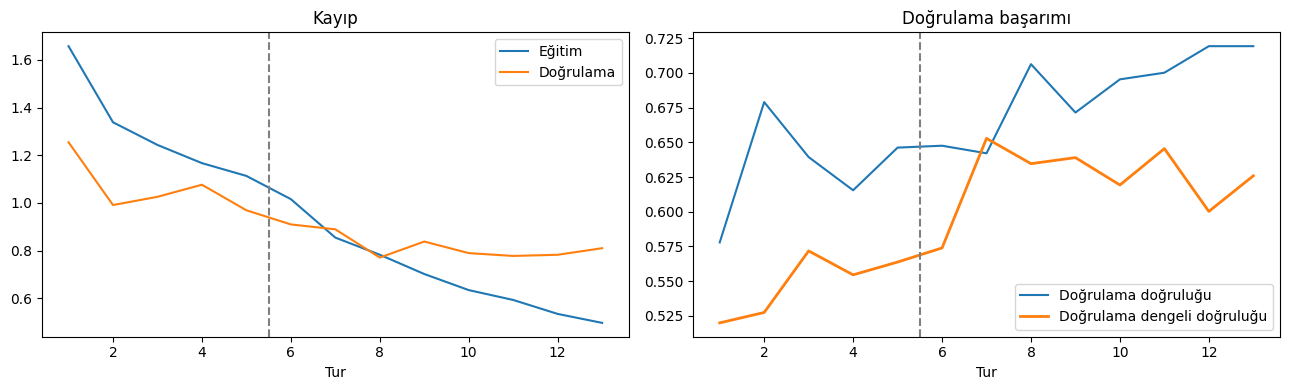

In [9]:
h = {k: gecmis1.history[k] + gecmis2.history.get(k, []) for k in gecmis1.history}
turlar = np.arange(1, len(h['loss']) + 1)
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(turlar, h['loss'], label='Eğitim'); ax[0].plot(turlar, h['val_loss'], label='Doğrulama')
ax[0].set_title('Kayıp'); ax[0].set_xlabel('Tur'); ax[0].legend()
ax[1].plot(turlar, h['val_accuracy'], label='Doğrulama doğruluğu')
ax[1].plot(turlar, kayit.gecmis, label='Doğrulama dengeli doğruluğu', linewidth=2)
ax[1].set_title('Doğrulama başarımı'); ax[1].set_xlabel('Tur'); ax[1].legend()
for a in ax: a.axvline(EPOCH_BAS + 0.5, color='gray', linestyle='--')
plt.tight_layout(); plt.savefig(f'{PROJE}/results/02_egitim_egrisi.png', dpi=150); plt.show()
pd.DataFrame({**h, 'val_bal_acc': kayit.gecmis}).to_csv(f'{PROJE}/results/02_egitim_gecmisi.csv', index_label='tur')

## 10. En iyi modeli doğrulama kümesinde değerlendir
Kaydedilen **en iyi** model yüklenir. Test kümesine hâlâ dokunmuyoruz; o, Adım 3'te kalibrasyondan sonra yalnızca bir kez kullanılacak.

In [10]:
from sklearn.metrics import classification_report, confusion_matrix, f1_score, roc_auc_score

en_iyi_model = keras.models.load_model(MODEL_YOLU)
logit_dog = en_iyi_model.predict(dogrulama_ds, verbose=0)
olasilik_dog = tf.nn.softmax(logit_dog).numpy()
tahmin_dog = olasilik_dog.argmax(1)

metrikler = {
    'dengeli_dogruluk': float(balanced_accuracy_score(y_dogrulama, tahmin_dog)),
    'dogruluk': float((tahmin_dog == y_dogrulama).mean()),
    'makro_f1': float(f1_score(y_dogrulama, tahmin_dog, average='macro')),
    'makro_auc': float(roc_auc_score(y_dogrulama, olasilik_dog, multi_class='ovr', average='macro')),
}
rapor = classification_report(y_dogrulama, tahmin_dog, labels=range(len(SINIFLAR)),
                              target_names=[SINIF_ADI[s] for s in SINIFLAR], digits=3,
                              output_dict=True, zero_division=0)
metrikler['melanom_duyarliligi'] = float(rapor['Melanom']['recall'])

print('DOĞRULAMA SONUÇLARI')
for k, v in metrikler.items():
    print(f'  {k:22s}: {v:.4f}')
print()
print(classification_report(y_dogrulama, tahmin_dog, labels=range(len(SINIFLAR)),
                            target_names=[SINIF_ADI[s] for s in SINIFLAR], digits=3, zero_division=0))

DOĞRULAMA SONUÇLARI
  dengeli_dogruluk      : 0.6528
  dogruluk              : 0.6421
  makro_f1              : 0.4866
  makro_auc             : 0.9289
  melanom_duyarliligi   : 0.5833

                         precision    recall  f1-score   support

        Aktinik keratoz      0.474     0.628     0.540        43
 Bazal hücreli karsinom      0.452     0.528     0.487        72
         Benign keratoz      0.484     0.545     0.513       167
          Dermatofibrom      0.107     0.706     0.186        17
                Melanom      0.353     0.583     0.439       168
Melanositik nevüs (ben)      0.965     0.671     0.791       975
        Vasküler lezyon      0.299     0.909     0.449        22

               accuracy                          0.642      1464
              macro avg      0.448     0.653     0.487      1464
           weighted avg      0.780     0.642     0.685      1464



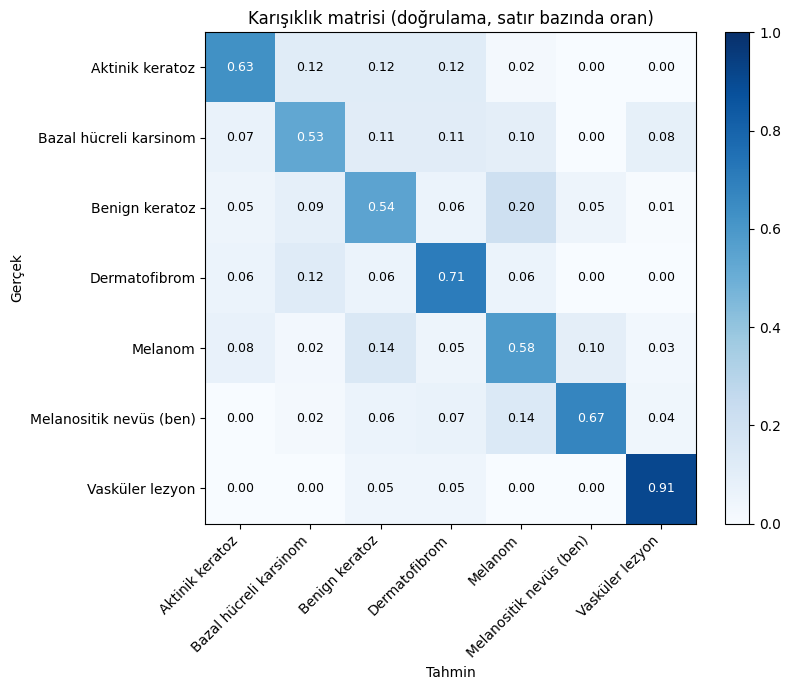

In [11]:
km = confusion_matrix(y_dogrulama, tahmin_dog, labels=range(len(SINIFLAR)), normalize='true')
fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(km, cmap='Blues', vmin=0, vmax=1)
etiket = [SINIF_ADI[s] for s in SINIFLAR]
ax.set_xticks(range(len(etiket)), etiket, rotation=45, ha='right'); ax.set_yticks(range(len(etiket)), etiket)
for i in range(len(etiket)):
    for j in range(len(etiket)):
        ax.text(j, i, f'{km[i, j]:.2f}', ha='center', va='center', color='white' if km[i, j] > 0.5 else 'black', fontsize=9)
ax.set_xlabel('Tahmin'); ax.set_ylabel('Gerçek'); ax.set_title('Karışıklık matrisi (doğrulama, satır bazında oran)')
plt.colorbar(im, fraction=0.046); plt.tight_layout()
plt.savefig(f'{PROJE}/results/02_karisiklik_matrisi.png', dpi=150); plt.show()

## 11. Sonuçları kaydet
Doğrulama logitleri Adım 3'teki kalibrasyon için gerekli.

In [12]:
np.save(f'{PROJE}/models/{MODEL_ADI}_dogrulama_logit.npy', logit_dog)
np.save(f'{PROJE}/models/{MODEL_ADI}_dogrulama_y.npy', y_dogrulama)
pd.DataFrame(rapor).T.to_csv(f'{PROJE}/results/02_siniflandirma_raporu.csv')
with open(f'{PROJE}/results/02_dogrulama_metrikleri.json', 'w', encoding='utf-8') as f:
    json.dump({'model': MODEL_ADI, 'img': IMG, 'siniflar': SINIFLAR, **metrikler,
               'ayarlar': {'batch': BATCH, 'epoch_bas': EPOCH_BAS, 'epoch_ince': EPOCH_INCE,
                           'lr_bas': LR_BAS, 'lr_ince': LR_INCE, 'acilan_katman': ACILACAK,
                           'tur_sayisi': len(kayit.gecmis)}},
              f, ensure_ascii=False, indent=2)
print('Kaydedildi:')
for p in ['models/' + MODEL_ADI + '.keras', 'models/' + MODEL_ADI + '_dogrulama_logit.npy',
          'results/02_egitim_egrisi.png', 'results/02_karisiklik_matrisi.png',
          'results/02_siniflandirma_raporu.csv', 'results/02_dogrulama_metrikleri.json', 'results/02_egitim_gecmisi.csv']:
    print(' ', p, '✓' if os.path.exists(f'{PROJE}/{p}') else 'YOK!')

Kaydedildi:
  models/cnn_b0.keras ✓
  models/cnn_b0_dogrulama_logit.npy ✓
  results/02_egitim_egrisi.png ✓
  results/02_karisiklik_matrisi.png ✓
  results/02_siniflandirma_raporu.csv ✓
  results/02_dogrulama_metrikleri.json ✓
  results/02_egitim_gecmisi.csv ✓
